# Malli 1 – Oma CNN-malli


In [1]:
import os
os.environ["KERAS_BACKEND"] = "tensorflow"
import matplotlib.pyplot as plt
import numpy as np
import keras
from keras import layers
from keras.models import Sequential
from keras.callbacks import EarlyStopping
from keras.utils import image_dataset_from_directory
from scripts.notebook_scripts import collect_images, plot_images

Tässä muistikirjassa käsitellään oman CNN-mallin luomista. Malli koulutetaan itse ottamillamme kuvilla.

Malli lukee kuvat kansiosta dataset/

Kuva-aineisto sisältää 5 luokkaa, ja se on jaettu kolmeen osaan (70 % / 15 % / 15 %). Aineistosta 70 % käytetään koulutukseen, 15 % validointiin ja viimeiset 15 % testaukseen.

Kuvien 5 luokkaa ovat:
- fork
- knife
- mug
- pen
- plate

Kaikki kuvat muutetaan kokoon **224 × 224 pikseliä** ennen koulutusta.


## Kuva-aineiston lataaminen

Kuvat ladataan Keras-kirjaston tarjoamalla `image_dataset_from_directory`-työkalulla.

Aineisto on järjestetty erillisiin kansioihin seuraavasti:
- koulutusdata
- validointidata
- testidata

Jokainen kansio sisältää alikansioita, jotka vastaavat eri luokkia. Keras määrittää tunnisteet automaattisesti näiden kansioiden nimien perusteella.

Kuvat ladataan 32 kuvan erissä ja niiden koko muutetaan **224 × 224 pikseliin**, jotta ne ovat yhdenmukaisia neuroverkkoa varten.


In [2]:
batch_size = 32
img_size = (224, 224) # every image is 224x224 pixels

train_dataset = image_dataset_from_directory(
    "dataset/train",
    image_size=img_size,
    batch_size=batch_size,
    label_mode="categorical"
)

validation_dataset = image_dataset_from_directory(
    "dataset/validation",
    image_size=img_size,
    batch_size=batch_size,
    label_mode="categorical"
)

test_dataset = image_dataset_from_directory(
    "dataset/test",
    image_size=img_size,
    batch_size=batch_size,
    label_mode="categorical"
)

Found 175 files belonging to 5 classes.
Found 40 files belonging to 5 classes.
Found 35 files belonging to 5 classes.


## Datan augmentointi

Koska kuva-aineisto on suhteellisen pieni, datan augmentointia käytetään koulutusdatan monipuolisuuden keinotekoiseen lisäämiseen.

Datan augmentointi auttaa mallia yleistämään paremmin luomalla koulutuksen aikana hieman muunneltuja versioita alkuperäisistä koulutuskuvista.

Kuville tehdään seuraavat muunnokset:

- Satunnainen vaakasuuntainen peilaus
- Satunnainen kierto
- Satunnainen zoomaus
- Satunnainen siirto
- Kirkkauden satunnainen säätö
- Kontrastin satunnainen säätö

Nämä muunnokset auttavat mallia kestämään paremmin valaistuksen, asennon ja kohteiden sijainnin vaihtelua.


In [3]:
data_augmentation = keras.Sequential(
    [
        keras.Input(shape=(224, 224, 3)),
        layers.RandomFlip("horizontal"),    # Randomly flip images horizontally
        layers.RandomRotation(0.2),         # Randomly rotate images by up to 20%
        layers.RandomZoom(0.2),             # Randomly zoom images by up to 20%
        layers.RandomTranslation(0.1, 0.1), # Randomly translate images by up to 10% in both directions
        layers.RandomBrightness(0.2),       # Randomly adjust brightness by up to 20%
        layers.RandomContrast(0.2),         # Randomly adjust contrast by up to 20%
    ]
)

Esimerkki käytetyn datan augmentoinnin visualisoinnista:


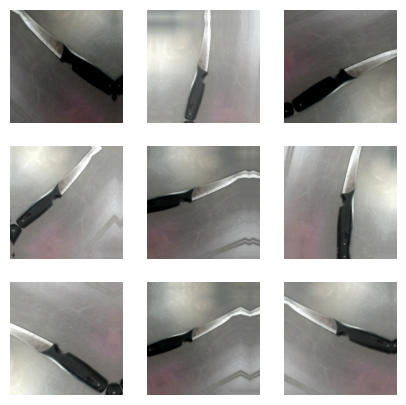

In [4]:
plt.figure(figsize=(5, 5))
for images, _ in train_dataset.take(1):
    for i in range(9):
        augmented_images = data_augmentation(images, training=True)
        ax = plt.subplot(3, 3, i+1)
        plt.imshow(augmented_images[0].numpy().astype("uint8"))
        plt.axis("off")

## CNN-mallin arkkitehtuuri

Malli rakennetaan peräkkäisistä kerroksista koostuvalla konvoluutioneuroverkkoarkkitehtuurilla (CNN).

Verkko koostuu useista konvoluutiokerroksista, joita seuraavat pooling-kerrokset. Niiden avulla kuvista poimitaan paikkatietoon liittyviä piirteitä.

### Arkkitehtuurin yleiskuvaus:

1. **Datan augmentointikerros** – tekee koulutuskuville satunnaisia muunnoksia
2. **Skaalauskerros** – normalisoi pikseliarvot väliltä [0,255] välille [0,1]
3. **Konvoluutiokerrokset** – poimivat kuvista visuaalisia piirteitä
4. **MaxPooling-kerrokset** – pienentävät piirre-esitysten spatiaalisia mittoja ja laskennallista kuormitusta
5. **Dropout-kerrokset** – auttavat ehkäisemään ylisovittamista
6. **GlobalAveragePooling-kerros** – pienentää piirre-esityksiä ennen luokittelijaa
7. **Dense-kerros** – oppii korkeamman tason piirre-esityksiä
8. **Softmax-ulostulokerros** – tuottaa todennäköisyydet viidelle luokalle

Mallissa on noin **28 000 koulutettavaa parametria**, joten se on suhteellisen kevyt ja soveltuu pieneen kuva-aineistoon.


In [5]:
model = Sequential([
    data_augmentation,
    layers.Rescaling(1./255),

    layers.Conv2D(16, (3,3), activation='relu'),
    layers.MaxPooling2D(2,2),
    layers.Dropout(0.2),

    layers.Conv2D(32, (3,3), activation='relu'),
    layers.MaxPooling2D(2,2),
    layers.Dropout(0.2),

    layers.Conv2D(64, (3,3), activation='relu'),
    layers.MaxPooling2D(2,2),
    layers.Dropout(0.2),

    layers.GlobalAveragePooling2D(),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(5, activation='softmax')
])

## Mallin koulutus

Malli koulutetaan käyttämällä **Adam-optimoijaa** ja **kategorista ristientropiahäviötä (categorical crossentropy)**, joka soveltuu moniluokkaisiin luokitteluongelmiin.

Ylisovittamisen välttämiseksi koulutuksessa käytetään **Early Stopping** -menetelmää. Se seuraa validointihäviötä ja keskeyttää koulutuksen, jos mallin suorituskyky ei enää parane.

Koulutusparametrit:
- Koulutuskierrosten enimmäismäärä: 50
- Eräkoko: 32
- Early Stopping -menetelmän kärsivällisyys: 5 kierrosta

Koulutuksen aikana malli oppii tunnistamaan visuaalisia piirteitä, joiden avulla viisi esineluokkaa voidaan erottaa toisistaan.


In [6]:
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

In [7]:
 # batch_size None
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ sequential (Sequential)              │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ rescaling (Rescaling)                │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d (Conv2D)                      │ (None, 222, 222, 16)        │             448 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 111, 111, 16)        │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 111, 111, 16)        │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 109, 109, 32)        │           4,640 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 54, 54, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 54, 54, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 52, 52, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 26, 26, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_2 (Dropout)                  │ (None, 26, 26, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 64)                  │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 64)                  │           4,160 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_3 (Dropout)                  │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 5)                   │             325 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 28,069 (109.64 KB)

 Trainable params: 28,069 (109.64 KB)

 Non-trainable params: 0 (0.00 B)

In [8]:
early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

history = model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=50,
    callbacks=[early_stop],
    verbose=0
)

C:\Users\taifj\anaconda3\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


## Mallin arviointi

Koulutuksen jälkeen mallia arvioidaan **testiaineistolla**, joka sisältää kuvia, joita malli ei ole aiemmin nähnyt.

Tämä antaa puolueettoman arvion mallin suorituskyvystä todellisissa käyttötilanteissa.

Arvioinnissa raportoidaan:
- **Testihäviö**
- **Testitarkkuus**

Tässä kokeessa malli saavutti testiaineistolla **77 %:n testitarkkuuden**. Tulos on hyvä, kun otetaan huomioon aineiston pieni koko ja joidenkin luokkien visuaalinen samankaltaisuus.


In [9]:
test_loss, test_acc = model.evaluate(test_dataset)
print(f"Test accuracy: {test_acc:.2f}")

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.7143 - loss: 0.9253 
Test accuracy: 0.71


## Koulutuksen suorituskyvyn visualisointi

Koulutusprosessin ymmärtämiseksi paremmin piirretään kuvaajat seuraavista:

- **Koulutus- ja validointitarkkuus**
- **Koulutus- ja validointihäviö**

Käyrien avulla voidaan analysoida, onko malli:
- oppimassa tehokkaasti
- ylisovittamassa
- alisovittamassa

Ihannetilanteessa koulutus- ja validointikäyrät kehittyvät samaan suuntaan ja tasaantuvat koulutuksen edetessä.


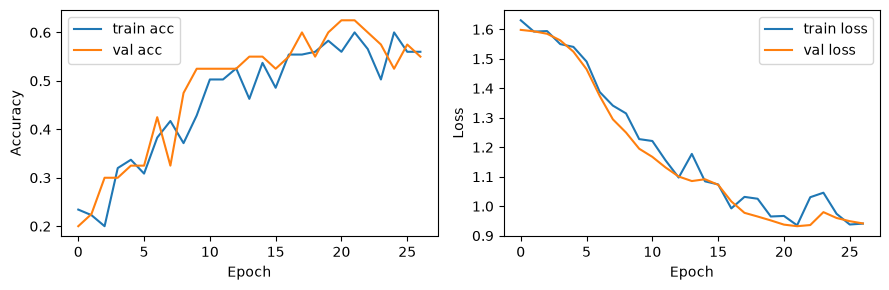

In [10]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 3))

ax1.plot(history.history['accuracy'], label='train acc')
ax1.plot(history.history['val_accuracy'], label='val acc')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Accuracy')
ax1.legend()

ax2.plot(history.history['loss'], label='train loss')
ax2.plot(history.history['val_loss'], label='val loss')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Loss')
ax2.legend()

plt.tight_layout()
plt.show()

## Ennusteiden analysointi

Mallin suorituskyvyn tarkempaa analysointia varten visualisoidaan esimerkkejä seuraavista:

- **Oikein luokitellut kuvat**
- **Väärin luokitellut kuvat**

Näin voidaan ymmärtää, missä tilanteissa malli toimii hyvin ja missä sillä on vaikeuksia.

Tarkastelemalla väärin luokiteltuja kuvia voidaan tunnistaa mahdollisia syitä virheisiin, kuten:
- keskenään samankaltaiset esineet
- poikkeavat valaistusolosuhteet
- haastavat katselukulmat
- taustan aiheuttamat häiriötekijät

Tällainen laadullinen analyysi on tärkeää, jotta mallin toimintaa voidaan ymmärtää pelkkien tarkkuuslukujen lisäksi.


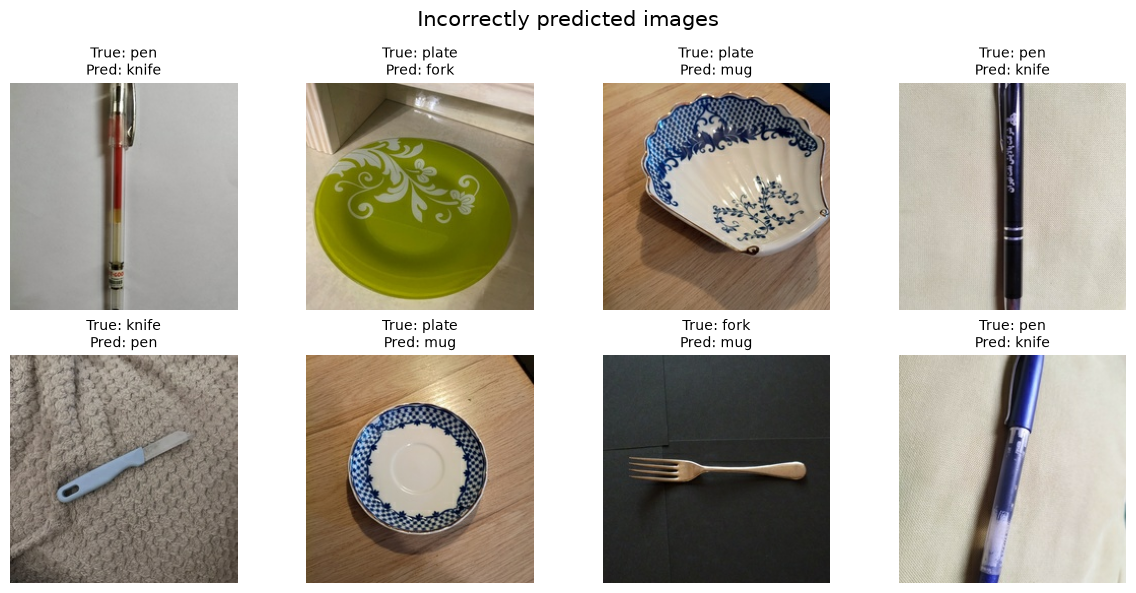

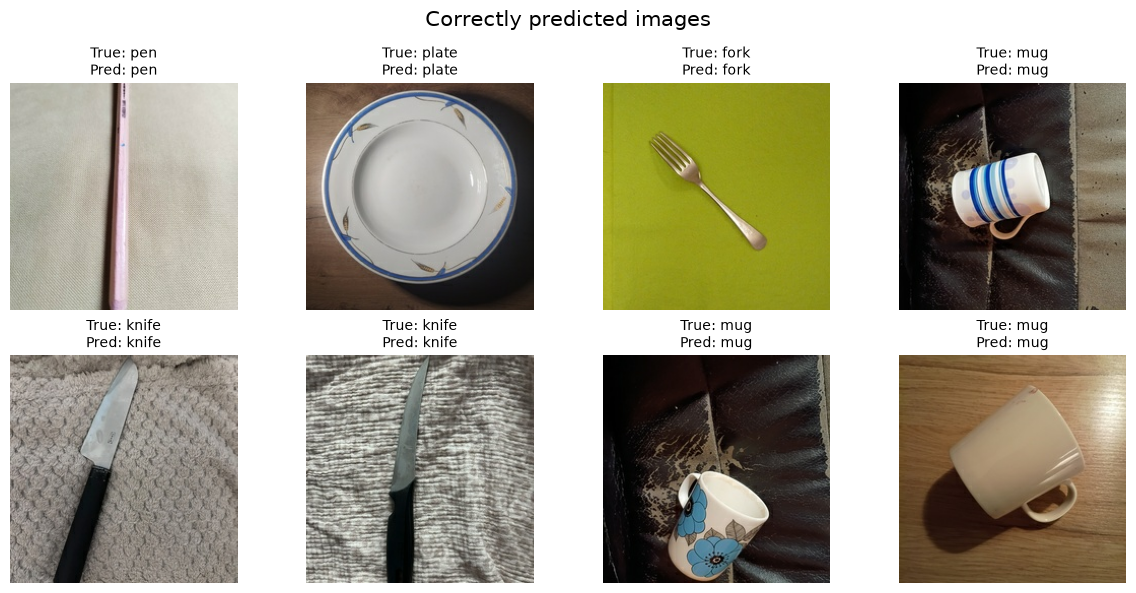

In [11]:
correct_images, wrong_images = collect_images(test_dataset, model)

plot_images(wrong_images, "Incorrectly predicted images")
plot_images(correct_images, "Correctly predicted images")

## Yhteenveto

Oma CNN-malli saavutti omalla kuva-aineistollamme **71 %:n testitarkkuuden**.

Kaiken kaikkiaan malli suoriutuu omilla kuvillamme melko hyvin, mutta visuaalisesti samankaltaisten luokkien välillä esiintyy edelleen sekaannuksia. Suurempi aineisto ja luokkakohtaiset lisäesimerkit todennäköisesti parantaisivat tarkkuutta entisestään.
